# Feature redundancy
Area and Convex_Area show very similar distributions, as observed from their boxplots and descriptive statistics. The scatter plot also shows an extremely strong linear relationship between the two features, which is supported by their correlation coefficient of approximately 1.00. Both features exhibit similar class patterns. Therefore, Area and Convex_Area contain highly similar information and may be redundant. To reduce potential redundancy in Logistic Regression, we will evaluate a reduced feature set by removing one of these features and compare its performance with the model using both features.

In [1]:
features_set1 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set2 = ['Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set3 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent']

In [2]:
import pandas as pd

train_set1 = pd.read_csv("train_set1.csv")

X_train_set1 = train_set1.drop(columns=["Target"])
y_train_set1 = train_set1["Target"]

train_set2 = pd.read_csv("train_set2.csv")

X_train_set2 = train_set2.drop(columns=["Target"])
y_train_set2 = train_set2["Target"]

train_set3 = pd.read_csv("train_set3.csv")

X_train_set3 = train_set3.drop(columns=["Target"])
y_train_set3 = train_set3["Target"]

# Train the model without using redundant feature 'Convex_Area'

# Feature scaling

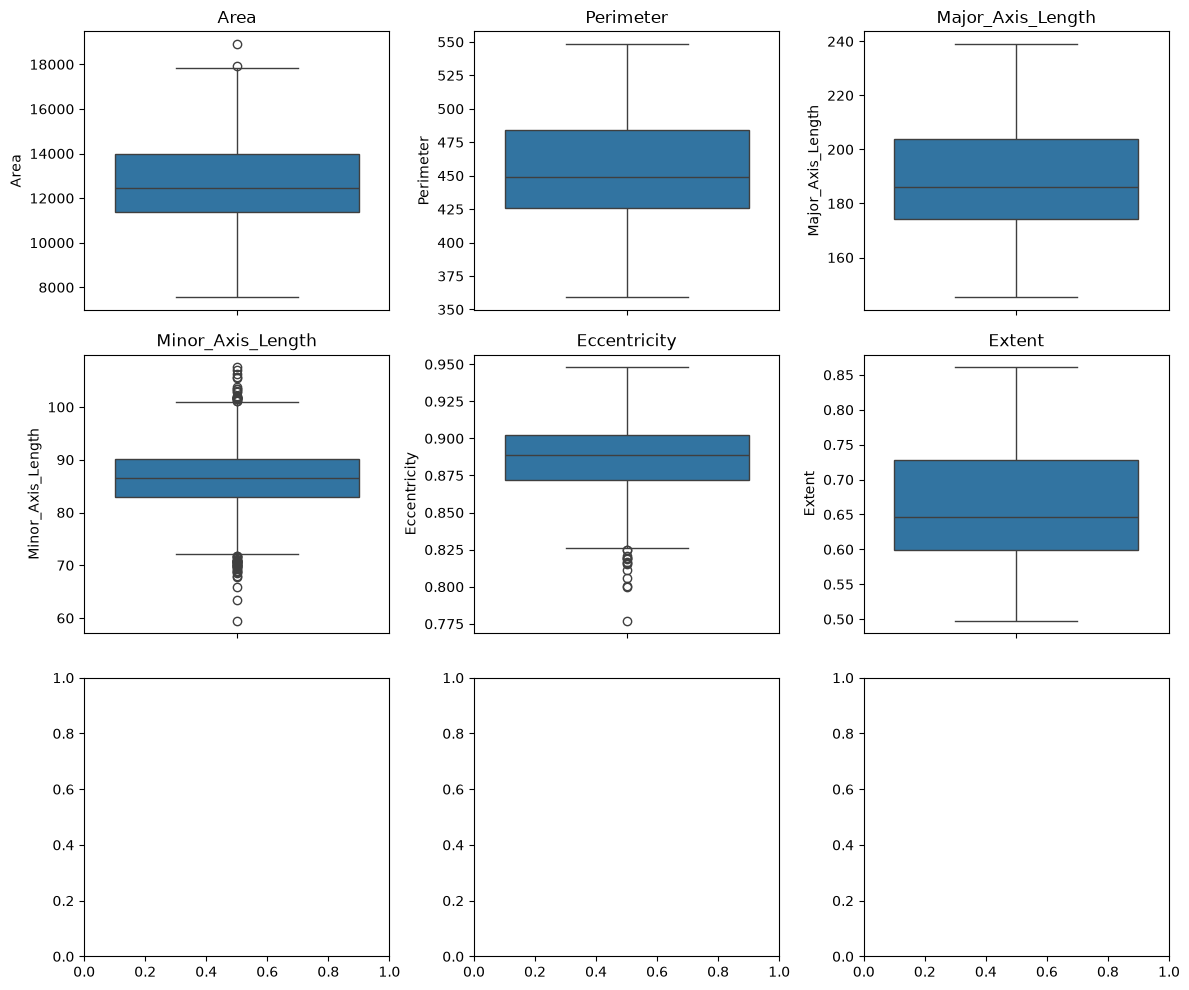

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(X_train_set3):
    sns.boxplot(y=X_train_set3[col], ax=axes[i])
    axes[i].set_title(col)


plt.tight_layout()
plt.show()

Features with outliers can scale using non-sensitive scaling method such as Robust scaling and others can scale using Standard Scaler

In [4]:
features_outliers = ['Eccentricity', 'Minor_Axis_Length', 'Area']
features_non_outliers  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set3[features_non_outliers])

In [6]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set3[features_outliers])

In [7]:
# Combine the scaled features

X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers,
        index=X_train_set3.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers,
        index=X_train_set3.index
    )
], axis=1)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np

# Create the model
logistic_model = LogisticRegression()

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    logistic_model,
    X_train_scaled,
    y_train_set3,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [9]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.92945037 0.93027071 0.93150123 0.93849938 0.9302993 ]
Validation accuracy: [0.93442623 0.93770492 0.9295082  0.91461412 0.93924466]
Mean training accuracy: 0.9320042002716992
Mean validation accuracy: 0.9310996258311125
Validation accuracy std: 0.008892044906765652
Mean F1: 0.9296474186771764
Mean Precision: 0.9299350048443449
Mean Recall: 0.9296408584334678


## Hyperparameter tuning

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

preprocessor = ColumnTransformer([
    ("standard", StandardScaler(), features_non_outliers),
    ("robust", RobustScaler(), features_outliers)
])

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring=scoring_metrics,
    refit="accuracy",
    return_train_score=True
)

grid_search.fit(X_train_set3, y_train_set3)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'model__C': 0.1}
Best CV Accuracy: 0.9330684540633664


In [11]:
# Obtain best model

best_logistic_model = grid_search.best_estimator_

In [12]:
results = pd.DataFrame(grid_search.cv_results_)

print(
    results[
        [
            "param_model__C",
            "mean_train_accuracy",
            "mean_test_accuracy"
        ]
    ]
)

   param_model__C  mean_train_accuracy  mean_test_accuracy
0            0.01             0.930610            0.930443
1            0.10             0.932825            0.933068
2            1.00             0.931594            0.931755
3           10.00             0.931758            0.931755
4          100.00             0.931840            0.931427


In [13]:
results = pd.DataFrame(grid_search.cv_results_)
best_results = results.loc[grid_search.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 0.1}
Mean Train Accuracy:      0.9328
Mean CV Accuracy:         0.9331
Mean CV Precision:        0.9321
Mean CV Recall:           0.9314
Mean CV F1-Score:         0.9316
Train-CV Accuracy Gap:    -0.0002
No strong overfitting signal based on this accuracy gap.


# Train the model without using redundant feature 'Area'

# Feature scaling

In [14]:
features_outliers_set2 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area']
features_non_outliers_set2  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [15]:
scaler = StandardScaler()

X_train_scaled_non_outliers_set2 = scaler.fit_transform(X_train_set2[features_non_outliers_set2])

In [16]:
scaler = RobustScaler()

X_train_scaled_outliers_set2 = scaler.fit_transform(X_train_set2[features_outliers_set2])

In [17]:
# Combine the scaled features

X_train_scaled_set2 = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers_set2,
        columns=features_non_outliers_set2,
        index=X_train_set2.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers_set2,
        columns=features_outliers_set2,
        index=X_train_set2.index
    )
], axis=1)

In [18]:
# Create the model
logistic_model = LogisticRegression()

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    logistic_model,
    X_train_scaled_set2,
    y_train_set2,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [19]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93068089 0.93027071 0.93396226 0.93890939 0.93111931]
Validation accuracy: [0.93934426 0.93770492 0.9295082  0.91625616 0.93924466]
Mean training accuracy: 0.9329885128219617
Mean validation accuracy: 0.9324116396134485
Validation accuracy std: 0.008856634192163513
Mean F1: 0.9309759827108944
Mean Precision: 0.9313489528326254
Mean Recall: 0.9308835990497881


## Hyperparameter tuning

In [20]:
preprocessor = ColumnTransformer([
    ("standard", StandardScaler(), features_non_outliers_set2),
    ("robust", RobustScaler(), features_outliers_set2)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring=scoring_metrics,
    refit="accuracy",
    return_train_score=True
)

grid_search.fit(X_train_set2, y_train_set2)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'model__C': 100}
Best CV Accuracy: 0.9330684540633664


In [21]:
# Obtain best model

best_logistic_model = grid_search.best_estimator_

In [22]:
results = pd.DataFrame(grid_search.cv_results_)

print(
    results[
        [
            "param_model__C",
            "mean_train_accuracy",
            "mean_test_accuracy"
        ]
    ]
)

   param_model__C  mean_train_accuracy  mean_test_accuracy
0            0.01             0.930692            0.930443
1            0.10             0.933235            0.932413
2            1.00             0.932743            0.931756
3           10.00             0.934547            0.932085
4          100.00             0.935039            0.933068


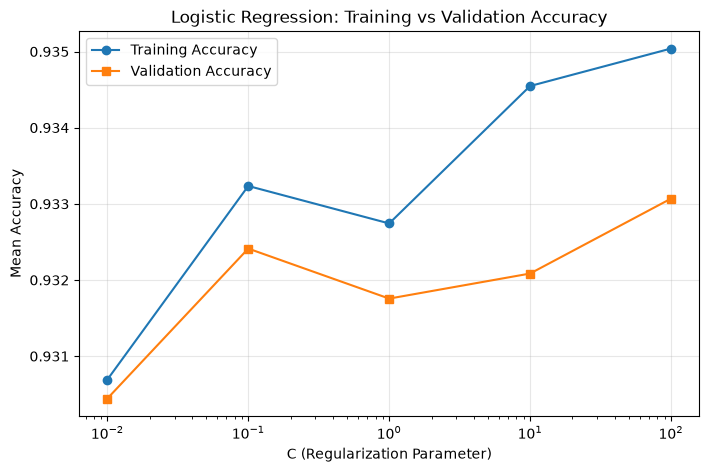

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results["param_model__C"],
    results["mean_train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    results["param_model__C"],
    results["mean_test_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

plt.xscale("log")
plt.xlabel("C (Regularization Parameter)")
plt.ylabel("Mean Accuracy")
plt.title("Logistic Regression: Training vs Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Evaluate best model

In [24]:
results = pd.DataFrame(grid_search.cv_results_)
best_results = results.loc[grid_search.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 100}
Mean Train Accuracy:      0.9350
Mean CV Accuracy:         0.9331
Mean CV Precision:        0.9320
Mean CV Recall:           0.9315
Mean CV F1-Score:         0.9316
Train-CV Accuracy Gap:    0.0020
No strong overfitting signal based on this accuracy gap.


# Train the model using both redundant features

# Feature scaling

In [25]:
features_outliers_set1 = ['Eccentricity', 'Minor_Axis_Length', 'Area', 'Convex_Area']
features_non_outliers_set1  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [26]:
scaler = StandardScaler()

X_train_scaled_non_outliers_set1 = scaler.fit_transform(X_train_set1[features_non_outliers_set1])

In [27]:
scaler = RobustScaler()

X_train_scaled_outliers_set1 = scaler.fit_transform(X_train_set1[features_outliers_set1])

In [28]:
# Combine the scaled features
X_train_scaled_set1 = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers_set1,
        columns=features_non_outliers_set1,
        index=X_train_set1.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers_set1,
        columns=features_outliers_set1,
        index=X_train_set1.index
    )
], axis=1)

In [29]:
# Create the model
logistic_model = LogisticRegression()

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    logistic_model,
    X_train_scaled_set1,
    y_train_set1,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [30]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93109106 0.93150123 0.9319114  0.93808938 0.93152932]
Validation accuracy: [0.93606557 0.93770492 0.93278689 0.91461412 0.93924466]
Mean training accuracy: 0.9328244775474825
Mean validation accuracy: 0.9320832323884896
Validation accuracy std: 0.008993480399207155
Mean F1: 0.9306419191847987
Mean Precision: 0.9310637346389591
Mean Recall: 0.9305970660984988


## Hyperparameter tuning

In [31]:
preprocessor = ColumnTransformer([
    ("standard", StandardScaler(), features_non_outliers_set1),
    ("robust", RobustScaler(), features_outliers_set1)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring=scoring_metrics,
    refit="accuracy",
    return_train_score=True
)

grid_search.fit(X_train_set1, y_train_set1)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'model__C': 100}
Best CV Accuracy: 0.9343820829632022


In [33]:
# Obtain best model

best_logistic_model = grid_search.best_estimator_

## Train test accuracy Evaluation

In [34]:
results = pd.DataFrame(grid_search.cv_results_)

print(
    results[
        [
            "param_model__C",
            "mean_train_accuracy",
            "mean_test_accuracy"
        ]
    ]
)

   param_model__C  mean_train_accuracy  mean_test_accuracy
0            0.01             0.929708            0.930115
1            0.10             0.932989            0.933397
2            1.00             0.932989            0.931755
3           10.00             0.934875            0.931756
4          100.00             0.935695            0.934382


In [35]:
results = pd.DataFrame(grid_search.cv_results_)
best_results = results.loc[grid_search.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 100}
Mean Train Accuracy:      0.9357
Mean CV Accuracy:         0.9344
Mean CV Precision:        0.9334
Mean CV Recall:           0.9327
Mean CV F1-Score:         0.9329
Train-CV Accuracy Gap:    0.0013
No strong overfitting signal based on this accuracy gap.


# Evaluate models removing outliers

## Outlier distribution of training and testing set
(Model without redundant feature 'Area')

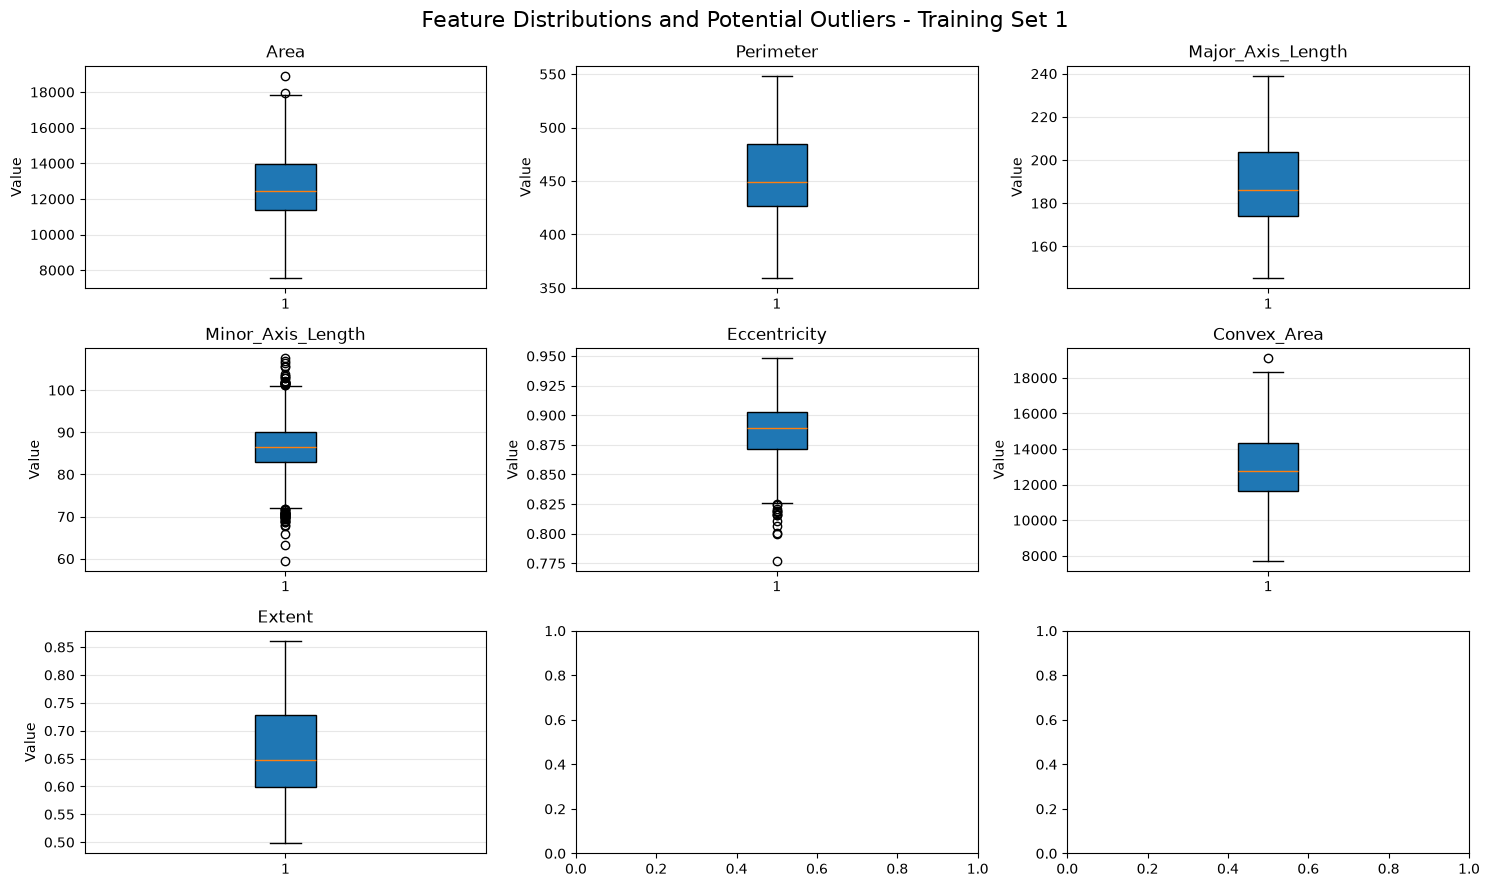

In [36]:
features_set1 = X_train_set1.columns

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set1):
    axes[i].boxplot(
        X_train_set1[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 1",
    fontsize=16
)

plt.tight_layout()
plt.show()

In training set, Minor_Axis_Length, Eccentricity and Convex area has outliers.

In [37]:
outlier_features = [
    "Minor_Axis_Length",
    "Eccentricity",
    "Convex_Area"
]

X_train_set1_clean = X_train_set1.copy()
y_train_set1_clean = y_train_set1.copy()

for feature in outlier_features:

    Q1 = X_train_set1_clean[feature].quantile(0.25)
    Q3 = X_train_set1_clean[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (
        (X_train_set1_clean[feature] >= lower_bound) &
        (X_train_set1_clean[feature] <= upper_bound)
    )

    X_train_set1_clean = X_train_set1_clean[mask]
    y_train_set1_clean = y_train_set1_clean.loc[X_train_set1_clean.index]

    print(f"{feature}")
    print(f"Lower bound: {lower_bound:.4f}")
    print(f"Upper bound: {upper_bound:.4f}")
    print(f"Remaining rows: {len(X_train_set1_clean)}")
    print()

Minor_Axis_Length
Lower bound: 71.9833
Upper bound: 101.0960
Remaining rows: 2991

Eccentricity
Lower bound: 0.8261
Upper bound: 0.9477
Remaining rows: 2977

Convex_Area
Lower bound: 7690.0000
Upper bound: 18290.0000
Remaining rows: 2977



In [38]:
# Removed rows count
print("Original training rows:", len(X_train_set1))
print("Clean training rows:", len(X_train_set1_clean))
print("Rows removed:", len(X_train_set1) - len(X_train_set1_clean))

Original training rows: 3048
Clean training rows: 2977
Rows removed: 71


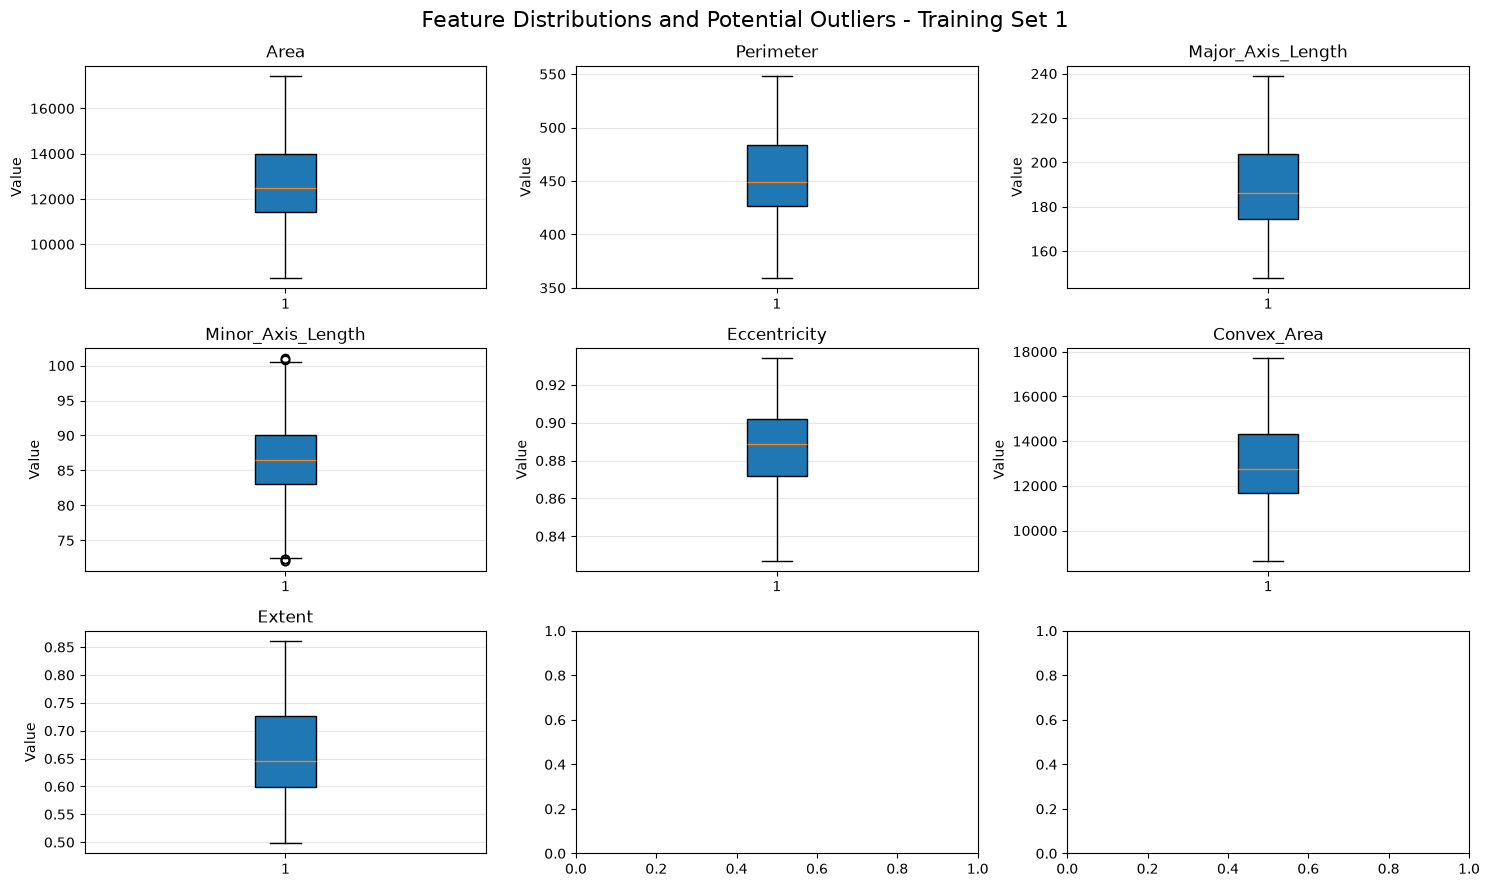

In [39]:
features_set1 = X_train_set1_clean.columns

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set1):
    axes[i].boxplot(
        X_train_set1_clean[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 1",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Train the model using cleaned training data

In [40]:
scaler = StandardScaler()

X_train_scaled_non_outliers_set1 = scaler.fit_transform(X_train_set1_clean[features_non_outliers_set1])

In [41]:
scaler = RobustScaler()

X_train_scaled_outliers_set1 = scaler.fit_transform(X_train_set1_clean[features_outliers_set1])

In [42]:
# Combine the scaled features

X_train_scaled_set1 = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers_set1,
        columns=features_non_outliers_set1,
        index=X_train_set1_clean.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers_set1,
        columns=features_outliers_set1,
        index=X_train_set1_clean.index
    )
], axis=1)

In [43]:
# Create the model
logistic_model = LogisticRegression()

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    logistic_model,
    X_train_scaled_set1,
    y_train_set1_clean,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [44]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.92944141 0.92902142 0.93240974 0.92905122 0.93324937]
Validation accuracy: [0.93456376 0.93288591 0.93109244 0.93277311 0.92268908]
Mean training accuracy: 0.9306346316398608
Mean validation accuracy: 0.930800857255654
Validation accuracy std: 0.004201967423735901
Mean F1: 0.9294111813129919
Mean Precision: 0.9298547227082798
Mean Recall: 0.9293257945599731


## Hyperparameter tuning

In [45]:
preprocessor = ColumnTransformer([
    ("standard", StandardScaler(), features_non_outliers_set1),
    ("robust", RobustScaler(), features_outliers_set1)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring=scoring_metrics,
    refit="accuracy",
    return_train_score=True
)

grid_search.fit(X_train_set1_clean, y_train_set1_clean)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'model__C': 100}
Best CV Accuracy: 0.9334888049179405


In [46]:
# Obtain best model

best_logistic_model = grid_search.best_estimator_

# Train test accuracy evaluation

In [47]:
results = pd.DataFrame(grid_search.cv_results_)

print(
    results[
        [
            "param_model__C",
            "mean_train_accuracy",
            "mean_test_accuracy"
        ]
    ]
)

   param_model__C  mean_train_accuracy  mean_test_accuracy
0            0.01             0.928703            0.928784
1            0.10             0.931474            0.931135
2            1.00             0.930719            0.930462
3           10.00             0.933490            0.930800
4          100.00             0.934666            0.933489


## Evaluate best model

In [48]:
results = pd.DataFrame(grid_search.cv_results_)
best_results = results.loc[grid_search.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 100}
Mean Train Accuracy:      0.9347
Mean CV Accuracy:         0.9335
Mean CV Precision:        0.9326
Mean CV Recall:           0.9319
Mean CV F1-Score:         0.9321
Train-CV Accuracy Gap:    0.0012
No strong overfitting signal based on this accuracy gap.


# Check class imbalance

In [49]:
class_distribution = pd.DataFrame({
    "Count": y_train_set2.value_counts(),
    "Percentage": y_train_set2.value_counts(normalize=True) * 100
})

print(class_distribution)

          Count  Percentage
Target                     
Osmancik   1744   57.217848
Cammeo     1304   42.782152


### Balance the classes using SMOTE

In [50]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_set1_balanced, y_train_set1_balanced = smote.fit_resample(
    X_train_set1,
    y_train_set1
)

In [51]:
class_distribution_balanced = pd.DataFrame({
    "Count": y_train_set1_balanced.value_counts(),
    "Percentage": y_train_set1_balanced.value_counts(normalize=True) * 100
})

print(class_distribution_balanced)

          Count  Percentage
Target                     
Osmancik   1744        50.0
Cammeo     1744        50.0


# Feature scaling

In [52]:
features_outliers_set1 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area']
features_non_outliers_set1  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [53]:
scaler = StandardScaler()

X_train_scaled_non_outliers_set1 = scaler.fit_transform(X_train_set1_balanced[features_non_outliers_set1])

In [54]:
scaler = RobustScaler()

X_train_scaled_outliers_set1 = scaler.fit_transform(X_train_set1_balanced[features_outliers_set1])

In [55]:
# Combine the scaled features

X_train_scaled_set1 = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers_set1,
        columns=features_non_outliers_set1,
        index=X_train_set1_balanced.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers_set1,
        columns=features_outliers_set1,
        index=X_train_set1_balanced.index
    )
], axis=1)

In [56]:
# Create the model
logistic_model = LogisticRegression()

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    logistic_model,
    X_train_scaled_set1,
    y_train_set1_balanced,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [57]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93046595 0.92903226 0.92759857 0.94159799 0.93228234]
Validation accuracy: [0.93696275 0.94555874 0.94269341 0.89526542 0.93543759]
Mean training accuracy: 0.9321954207649009
Mean validation accuracy: 0.93118358252519
Validation accuracy std: 0.01833428908684131
Mean F1: 0.9311753358454116
Mean Precision: 0.9314060367079519
Mean Recall: 0.9311835128281132


## Hyperparameter tuning

In [58]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

preprocessor = ColumnTransformer([
    ("standard", StandardScaler(), features_non_outliers_set1),
    ("robust", RobustScaler(), features_outliers_set1)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

pipeline_smote = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid_smote = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_search_smote = GridSearchCV(
    pipeline_smote,
    param_grid_smote,
    cv=5,
    scoring=scoring_metrics,
    refit="accuracy",
    return_train_score=True
)

grid_search_smote.fit(X_train_set1, y_train_set1)

print("Best Parameters:", grid_search_smote.best_params_)
print("Best CV Accuracy:", grid_search_smote.best_score_)

Best Parameters: {'model__C': 10}
Best CV Accuracy: 0.9311012409486124


In [59]:
# Obtain best model

best_logistic_model = grid_search_smote.best_estimator_

In [60]:
results = pd.DataFrame(grid_search_smote.cv_results_)

print(
    results[
        [
            "param_model__C",
            "mean_train_accuracy",
            "mean_test_accuracy"
        ]
    ]
)

   param_model__C  mean_train_accuracy  mean_test_accuracy
0            0.01             0.930528            0.930771
1            0.10             0.930692            0.930446
2            1.00             0.931430            0.929132
3           10.00             0.932087            0.931101
4          100.00             0.932497            0.931100


In [61]:
results = pd.DataFrame(grid_search_smote.cv_results_)
best_results = results.loc[grid_search_smote.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_smote.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 10}
Mean Train Accuracy:      0.9321
Mean CV Accuracy:         0.9311
Mean CV Precision:        0.9288
Mean CV Recall:           0.9317
Mean CV F1-Score:         0.9299
Train-CV Accuracy Gap:    0.0010
No strong overfitting signal based on this accuracy gap.


# FFS

In [62]:
features_non_outliers_set1 = [
    "Perimeter",
    "Major_Axis_Length",
    "Extent"
]

features_outliers_set1 = [
    "Minor_Axis_Length",
    "Eccentricity",
    "Convex_Area",
    "Area"
]

In [63]:

from sklearn.model_selection import StratifiedKFold, cross_validate

# Configure cross-validation
cv_ffs = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_C = 100

# Define evaluation metrics
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}


def build_logistic_pipeline(selected_features):

    selected_features = list(selected_features)

    standard_features = [
        f for f in features_non_outliers_set1
        if f in selected_features
    ]

    robust_features = [
        f for f in features_outliers_set1
        if f in selected_features
    ]

    transformers = []

    if standard_features:
        transformers.append(
            ("standard", StandardScaler(), standard_features)
        )

    if robust_features:
        transformers.append(
            ("robust", RobustScaler(), robust_features)
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            C=best_C,
            max_iter=2000,
            solver="lbfgs"
        ))
    ])


# Implement Forward Feature Selection
selected_features = []
remaining_features = X_train_set1.columns.tolist()
ffs_results = []

while remaining_features:

    candidate_results = []

    for feature in remaining_features:

        candidate_features = selected_features + [feature]

        pipeline = build_logistic_pipeline(candidate_features)

        # Evaluate all metrics using 5-fold CV
        scores = cross_validate(
            pipeline,
            X_train_set1[candidate_features],
            y_train_set1,
            cv=cv_ffs,
            scoring=scoring_metrics,
            return_train_score=True,
            n_jobs=-1
        )

        candidate_results.append({
            "Feature": feature,
            "Train Accuracy":
                scores["train_accuracy"].mean(),
            "Mean CV Accuracy":
                scores["test_accuracy"].mean(),
            "CV Std":
                scores["test_accuracy"].std(),
            "Precision":
                scores["test_precision"].mean(),
            "Recall":
                scores["test_recall"].mean(),
            "F1-Score":
                scores["test_f1"].mean()
        })

    # Select the feature with the highest mean CV accuracy
    candidate_results.sort(
        key=lambda x: x["Mean CV Accuracy"],
        reverse=True
    )

    best_candidate = candidate_results[0]

    selected_features.append(best_candidate["Feature"])
    remaining_features.remove(best_candidate["Feature"])

    ffs_results.append({
        "Step": len(selected_features),
        "Added Feature": best_candidate["Feature"],
        "Selected Features": selected_features.copy(),
        "Number of Features": len(selected_features),
        "Train Accuracy": best_candidate["Train Accuracy"],
        "Mean CV Accuracy": best_candidate["Mean CV Accuracy"],
        "CV Std": best_candidate["CV Std"],
        "Precision": best_candidate["Precision"],
        "Recall": best_candidate["Recall"],
        "F1-Score": best_candidate["F1-Score"]
    })


# Create and display the results table
ffs_df = pd.DataFrame(ffs_results)

display(
    ffs_df.style.format({
        "Train Accuracy": "{:.2%}",
        "Mean CV Accuracy": "{:.2%}",
        "CV Std": "{:.4f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)


# Identify the best feature subset
best_idx = ffs_df["Mean CV Accuracy"].idxmax()
best_row = ffs_df.loc[best_idx]

best_features_ffs = best_row["Selected Features"]

print("\nBest feature subset:", best_features_ffs)
print("Number of features:", len(best_features_ffs))
print(f"Train Accuracy: {best_row['Train Accuracy']:.4%}")
print(f"Mean CV Accuracy: {best_row['Mean CV Accuracy']:.4%}")
print(f"CV Standard Deviation: {best_row['CV Std']:.4f}")
print(f"Precision: {best_row['Precision']:.4%}")
print(f"Recall: {best_row['Recall']:.4%}")
print(f"F1-Score: {best_row['F1-Score']:.4%}")


,Step,Added Feature,Selected Features,Number of Features,Train Accuracy,Mean CV Accuracy,CV Std,Precision,Recall,F1-Score
0,1,Major_Axis_Length,['Major_Axis_Length'],1,93.04%,93.04%,0.0106,92.92%,92.92%,92.90%
1,2,Convex_Area,"['Major_Axis_Length', 'Convex_Area']",2,93.20%,93.27%,0.0108,93.18%,93.12%,93.13%
2,3,Area,"['Major_Axis_Length', 'Convex_Area', 'Area']",3,93.54%,93.47%,0.0072,93.39%,93.29%,93.33%
3,4,Perimeter,"['Major_Axis_Length', 'Convex_Area', 'Area', 'Perimeter']",4,93.53%,93.47%,0.0085,93.38%,93.30%,93.33%
4,5,Minor_Axis_Length,"['Major_Axis_Length', 'Convex_Area', 'Area', 'Perimeter', 'Minor_Axis_Length']",5,93.56%,93.50%,0.0073,93.41%,93.34%,93.36%
5,6,Eccentricity,"['Major_Axis_Length', 'Convex_Area', 'Area', 'Perimeter', 'Minor_Axis_Length', 'Eccentricity']",6,93.59%,93.44%,0.0074,93.34%,93.29%,93.30%
6,7,Extent,"['Major_Axis_Length', 'Convex_Area', 'Area', 'Perimeter', 'Minor_Axis_Length', 'Eccentricity', 'Extent']",7,93.56%,93.44%,0.0072,93.35%,93.27%,93.30%



Best feature subset: ['Major_Axis_Length', 'Convex_Area', 'Area', 'Perimeter', 'Minor_Axis_Length']
Number of features: 5
Train Accuracy: 93.5613%
Mean CV Accuracy: 93.5035%
CV Standard Deviation: 0.0073
Precision: 93.4111%
Recall: 93.3369%
F1-Score: 93.3620%


In [64]:

import joblib
from datetime import datetime

# 1. Get the best feature subset selected by FFS
selected_features = list(best_features_ffs)

print("Selected features:", selected_features)

# 2. Build the Logistic Regression pipeline
final_logistic_ffs = build_logistic_pipeline(selected_features)

# 3. Train the final model on the complete training set
final_logistic_ffs.fit(
    X_train_set1[selected_features],
    y_train_set1
)

# 4. Store the model and necessary metadata
model_bundle = {
    "model": final_logistic_ffs,
    "selected_features": selected_features,
    "model_name": "Logistic Regression - Set 1 FFS",
    "hyperparameters": {
        "C": best_C,
        "max_iter": 2000,
        "solver": "lbfgs"
    },
    "cv_metrics": {
        "train_accuracy": float(best_row["Train Accuracy"]),
        "mean_cv_accuracy": float(best_row["Mean CV Accuracy"]),
        "cv_std": float(best_row["CV Std"]),
        "precision_macro": float(best_row["Precision"]),
        "recall_macro": float(best_row["Recall"]),
        "f1_macro": float(best_row["F1-Score"])
    },
    "saved_at": datetime.now().isoformat()
}

# 5. Save everything in one file
joblib.dump(
    model_bundle,
    "logistic_regression_set1_ffs.joblib"
)

print("\nModel saved successfully!")
print("File: logistic_regression_set1_ffs.joblib")
print("Number of selected features:", len(selected_features))
print(f"Mean CV accuracy: {best_row['Mean CV Accuracy']:.2%}")


Selected features: ['Major_Axis_Length', 'Convex_Area', 'Area', 'Perimeter', 'Minor_Axis_Length']

Model saved successfully!
File: logistic_regression_set1_ffs.joblib
Number of selected features: 5
Mean CV accuracy: 93.50%


| Feature set | Train-Accuracy | CV-Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|--:|
| Set 3 | 93.28% | 93.31% | 93.21% | 93.14% | 93.16% | 
| Set 2 | 93.50% | 93.31% | 93.20% | 93.25% | 93.16% |
| Set 1 | 93.57% | 93.44% | 94.34% | 93.27% | 93.29% |
| Set 1 (SMOTE) | 93.21% | 93.11% | 92.88% | 93.17% | 92.99% |
| Set 1 (Remove outlier) | 93.47% | 93.35% | 93.26% | 93.19% |93.21% |
| Set 1 (FFS) | 93.56% | 93.50% | 93.41% | 93.34% | 93.36% |

## Conclusion: Logistic Regression Model Comparison

Based on the experimental results, **Set 1 with Forward Feature Selection (FFS)** is the preferred candidate among the evaluated Logistic Regression configurations. It achieved the highest mean cross-validation accuracy of **93.50%**, with a macro precision of **93.41%**, macro recall of **93.34%**, and macro F1-score of **93.36%**. Its training accuracy was 93.56%, resulting in a small training–CV accuracy gap of 0.06 percentage points.

The standard Set 1 configuration also performed well, achieving 93.44% mean CV accuracy and the highest reported macro precision of 94.34%. However, Set 1 (FFS) improved mean CV accuracy by only **0.06 percentage points** compared with standard Set 1. Therefore, the improvement in predictive performance is relatively small.

The SMOTE configuration achieved 93.11% CV accuracy, while the outlier-removal configuration achieved 93.35%. Neither outperformed Set 1 (FFS) in mean CV accuracy. These results suggest that applying SMOTE or removing outliers did not provide a clear overall improvement in this experiment.

Overall, **Set 1 (FFS) is the leading candidate** based on the reported cross-validation results. If FFS uses fewer input features, it may also simplify the model while maintaining predictive performance. However, the final choice should be confirmed by evaluating Set 1 (FFS) and the standard Set 1 model on the same untouched test set. Since FFS evaluates multiple feature subsets using cross-validation, its highest CV score may be optimistic. The independent test-set results should therefore be considered before declaring the final model.


In [65]:

# import joblib

# model_bundle = joblib.load("logistic_regression_set1_ffs.joblib")

# loaded_model = model_bundle["model"]
# selected_features = model_bundle["selected_features"]

# print("Model:", model_bundle["model_name"])
# print("Required features:", selected_features)
# print("CV metrics:", model_bundle["cv_metrics"])
#